# Capstone – Fake news detector
## Notebook 1 – Data exploration

**Goal of this notebook:** understand the dataset before building any model: its size, its quality, the balance between classes, and above all its **biases** (clues that let a model "cheat" without understanding the content).

**Dataset:** [GonzaloA/fake_news](https://huggingface.co/datasets/GonzaloA/fake_news) – about 40k English news articles, built from several Kaggle fake news datasets.

| Column | Meaning |
|--------|---------|
| `title` | headline of the article |
| `text` | body of the article |
| `label` | **1 = real**, **0 = fake** |

Techniques used (from the course): loading a Hugging Face dataset (Lab 4.2), regular expressions (Lab 1), tokenization / stop words / lemmatization (Lab 2), frequent words, word clouds, bigrams and TF-IDF per category (Lab 3.1).

Grading criterion covered: **Problem and data (4 pts)** – *real data, understood and explored (size, quality, biases)*.

## Setup

In [16]:
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from datasets import load_dataset
from nltk import ngrams
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from wordcloud import WordCloud

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(pkg, quiet=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 200)
RANDOM_STATE = 42

# Part 1 – Load the data

The dataset comes already split into `train`, `validation` and `test`. The three parquet files were downloaded from the *Files and versions* tab of the Hugging Face page into `data/` (this folder is not pushed to GitHub: 170 MB > 50 MB limit). If they are missing, they are downloaded with `load_dataset`.

We put the three splits in one DataFrame with a `split` column, so we can explore everything at once and still know where each article comes from.

In [17]:
from pathlib import Path

DATA_DIR = Path("../data")
SPLITS = ["train", "validation", "test"]

frames = []
for split_name in SPLITS:
    path = DATA_DIR / f"{split_name}-00000-of-00001.parquet"
    if path.exists():
        part = pd.read_parquet(path)
    else:  # fallback: download from Hugging Face
        part = load_dataset("GonzaloA/fake_news", split=split_name).to_pandas()
    part["split"] = split_name
    frames.append(part)
    print(f"{split_name:<10}: {len(part)} rows")

df = pd.concat(frames, ignore_index=True)
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
df["label_name"] = df["label"].map({1: "real", 0: "fake"})
print(df.shape)
df.head()

train     : 24353 rows
validation: 8117 rows
test      : 8117 rows
(40587, 5)


,title,text,label,split,label_name
0,‘Maury’ Show Official Facebook Posts F*CKED UP Caption On Guest That Looks Like Ted Cruz (IMAGE),"Maury is perhaps one of the trashiest shows on television today. It s right in line with the likes of the gutter trash that is Jerry Springer, and the fact that those shows are still on the air wi...",0,train,fake
1,Trump’s Favorite News Channel Tries To Soothe His Battered Ego – Gets Taken To The Cleaners,"Yesterday, after the father of one of the UCLA players arrested in China failed to show Trump proper gratitude for getting his kid released, Trump, predictably, went to Twitter to grouse about it....",0,train,fake
2,"Russia warns Iraq, Kurds not to destabilize Middle East after Kurdish vote","MOSCOW (Reuters) - Russia on Wednesday warned Iraq and the Kurds against taking any steps that might destabilize the Middle East after a Kurdish independence referendum, encouraging both sides to ...",1,train,real
3,WATCH STEVE SCALISE Throw A Strike At The Nationals Baseball Game [Video],"House Majority Whip Steve Scalise (R., La.) threw a strike in his ceremonial first pitch at the Washington National s opening-round playoff game Friday night, which was also his birthday.Scalise w...",0,train,fake
4,Trump Will HATE What Stephen Colbert Just Did To Him – It’s Pure Comedy Genius (VIDEO),"It can be said that Late Show host Stephen Colbert clearly gives no f*cks about what Donald Trump thinks of him. In addition, if Trump were to decide to angry-tweet Colbert in retaliation, you kno...",0,train,fake


# Part 2 – Quality of the data

We check missing values, empty texts and duplicates. Duplicates matter a lot: if the same article appears in `train` **and** in `test`, the test score will be too optimistic (the model has already seen the answer).

In [18]:
print("Missing values per column:")
print(df.isna().sum(), "\n")

df["title"] = df["title"].fillna("")
df["text"] = df["text"].fillna("")

empty_text = df["text"].str.strip() == ""
empty_title = df["title"].str.strip() == ""
print(f"Empty texts : {empty_text.sum()} ({empty_text.mean():.2%})")
print(f"Empty titles: {empty_title.sum()} ({empty_title.mean():.2%})")
print("\nEmpty texts by class:")
print(df[empty_text]["label_name"].value_counts())

Missing values per column:
title         0
text          0
label         0
split         0
label_name    0
dtype: int64 

Empty texts : 2 (0.00%)
Empty titles: 0 (0.00%)

Empty texts by class:
label_name
fake    2
Name: count, dtype: int64


In [19]:
dup_text = df.duplicated(subset="text", keep=False) & ~empty_text
dup_title = df.duplicated(subset="title", keep=False) & ~empty_title
print(f"Rows whose text appears more than once : {dup_text.sum()} ({dup_text.mean():.2%})")
print(f"Rows whose title appears more than once: {dup_title.sum()} ({dup_title.mean():.2%})")

# Same text but different labels = contradictory data
conflicts = df[~empty_text].groupby("text")["label"].nunique()
print(f"Texts that appear with BOTH labels: {(conflicts > 1).sum()}")

Rows whose text appears more than once : 0 (0.00%)
Rows whose title appears more than once: 982 (2.42%)
Texts that appear with BOTH labels: 0


In [20]:
# Leakage between splits: texts of validation/test that are also in train
train_texts = set(df.loc[(df["split"] == "train") & ~empty_text, "text"])
for split_name in ["validation", "test"]:
    texts = df.loc[(df["split"] == split_name) & ~empty_text, "text"]
    overlap = texts.isin(train_texts)
    print(f"{split_name:<10}: {overlap.sum()} articles also in train ({overlap.mean():.2%})")

validation: 0 articles also in train (0.00%)
test      : 0 articles also in train (0.00%)


**Decision to take for the modelling notebook:** remove empty texts and duplicates, and make sure no test article is also in train (we may rebuild our own split after deduplication).

# Part 3 – Class balance

Is there the same number of fake and real articles? If the classes are very unbalanced, accuracy alone is misleading and we should also look at precision, recall and F1-score.

label_name,fake,real,All
split,,,
test,3782,4335,8117
train,11158,13195,24353
validation,3723,4394,8117
All,18663,21924,40587


label_name,fake,real
split,,
test,0.466,0.534
train,0.458,0.542
validation,0.459,0.541


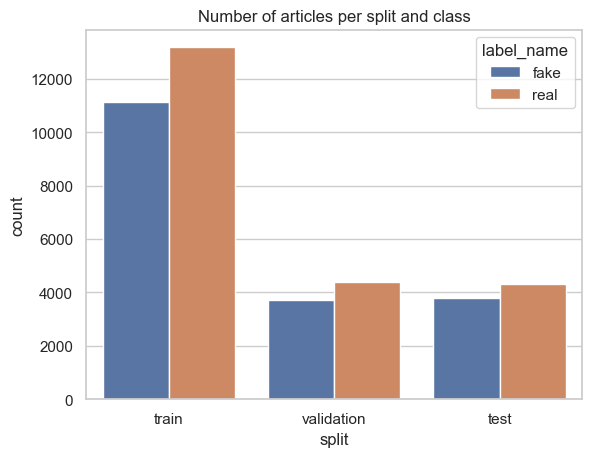

In [21]:
counts = pd.crosstab(df["split"], df["label_name"], margins=True)
display(counts)
display(pd.crosstab(df["split"], df["label_name"], normalize="index").round(3))

ax = sns.countplot(data=df, x="split", hue="label_name", order=["train", "validation", "test"])
ax.set_title("Number of articles per split and class")
plt.show()

# Part 4 – Length of the articles

Fake and real articles may not have the same length. If they are very different, the length itself is a signal the model can use – useful, but also a possible bias.

label_name            fake     real
title_words count  18663.0  21924.0
            mean      14.1      9.9
            std        4.2      1.9
            min        1.0      1.0
            25%       12.0      9.0
            50%       14.0     10.0
            75%       16.0     11.0
            max       67.0     29.0
text_words  count  18663.0  21924.0
            mean     428.8    390.1
            std      375.7    301.2
            min        0.0      1.0
            25%      269.0    145.0
            50%      374.0    358.0
            75%      505.0    526.0
            max     8135.0   5828.0

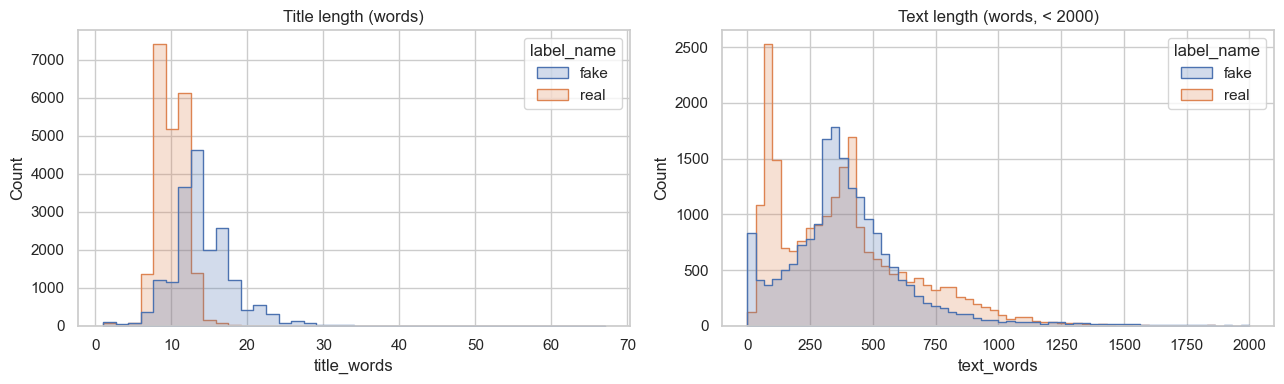

In [22]:
df["title_words"] = df["title"].str.split().str.len()
df["text_words"] = df["text"].str.split().str.len()

display(df.groupby("label_name")[["title_words", "text_words"]].describe().T.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="title_words", hue="label_name", bins=40, ax=axes[0], element="step")
axes[0].set_title("Title length (words)")
sns.histplot(data=df[df["text_words"] < 2000], x="text_words", hue="label_name",
             bins=60, ax=axes[1], element="step")
axes[1].set_title("Text length (words, < 2000)")
plt.tight_layout()
plt.show()

# Part 5 – Looking for biases (style and source clues)

The real articles of this kind of dataset often come from the **Reuters** news agency, and their text usually starts with a *dateline* such as `WASHINGTON (Reuters) -`. A model can learn "Reuters ⇒ real" without understanding anything about the news. This is a **data leak**: on a real article from *Le Monde* or the BBC, the clue would not be there.

We measure several such clues with regular expressions (Lab 1) and compare them between the two classes.

In [23]:
clues = {
    "mentions '(Reuters)'": df["text"].str.contains(r"\(Reuters\)", regex=True),
    "starts with a dateline 'CITY (Reuters) -'": df["text"].str.match(r"^\s*[A-Z][A-Za-z .,/'-]{1,60}\(Reuters\)\s*-"),
    "contains a URL": df["text"].str.contains(r"https?://|www\.", regex=True),
    "contains '@' (Twitter handle)": df["text"].str.contains(r"@\w+", regex=True),
    "contains 'Featured image' / 'image via'": df["text"].str.contains(r"featured image|image via", case=False, regex=True),
    "title has '!' or '?'": df["title"].str.contains(r"[!?]", regex=True),
    "title has a word in CAPITALS (>= 4 letters)": df["title"].str.contains(r"\b[A-Z]{4,}\b", regex=True),
    "title contains 'VIDEO' or 'WATCH'": df["title"].str.contains(r"\b(?:VIDEO|WATCH)\b", regex=True),
}

clue_table = pd.DataFrame({name: values.groupby(df["label_name"]).mean() for name, values in clues.items()}).T
clue_table = (clue_table * 100).round(1).rename(columns=lambda c: f"% of {c}")
clue_table

label_name,% of fake,% of real
mentions '(Reuters)',0.0,95.9
starts with a dateline 'CITY (Reuters) -',0.0,88.5
contains a URL,13.6,0.2
contains '@' (Twitter handle),25.3,1.3
contains 'Featured image' / 'image via',44.6,0.1
title has '!' or '?',15.0,0.7
title has a word in CAPITALS (>= 4 letters),71.5,2.4
title contains 'VIDEO' or 'WATCH',27.9,0.0


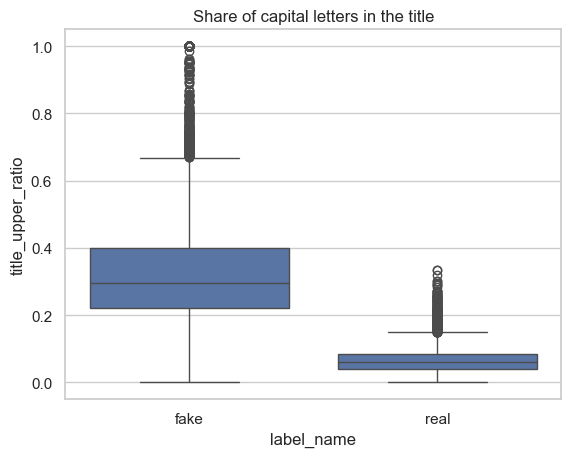

In [24]:
# Share of capital letters in the titles
def upper_ratio(s):
    letters = [c for c in s if c.isalpha()]
    return sum(c.isupper() for c in letters) / len(letters) if letters else 0

df["title_upper_ratio"] = df["title"].apply(upper_ratio)
sns.boxplot(data=df, x="label_name", y="title_upper_ratio")
plt.title("Share of capital letters in the title")
plt.show()

In [25]:
# Look at the first words of some articles of each class
for name in ["real", "fake"]:
    print(f"===== {name.upper()} =====")
    for t in df[df["label_name"] == name]["text"].sample(5, random_state=RANDOM_STATE):
        print("-", t[:150].replace("\n", " "))
    print()

===== REAL =====
- JERUSALEM (Reuters) - U.S. President Donald Trump remains committed and optimistic about achieving Israeli-Palestinian peace, his son-in-law and senio
- AUSTIN, Texas (Reuters) - The Texas House of Representatives gave preliminary approval on Tuesday to a new bill on showing identification when voting 
- WASHINGTON (Reuters) - Democratic presumptive presidential nominee Hillary Clinton could receive her rival Bernie Sanders’ endorsement at a public eve
- MOSCOW (Reuters) - Russian Foreign Minister Sergei Lavrov said at a meeting with his Iraqi counterpart that Moscow is committed to Iraq s territorial 
- CHICAGO (Reuters) - Illinois Republican Governor Bruce Rauner urged lawmakers on Friday to allow voters in 2018 to decide whether to change how politi

===== FAKE =====
-  As Americans we insist that no one should be targeted because of who they are, what they look like, who they love, what they worship. (Unless of cour
- Donald Trump apparently expects Democrats to 

**Decision to take for the modelling notebook:** remove the strongest source clues before training (for example the `CITY (Reuters) -` dateline and the word *Reuters*), then compare the score **with and without** this cleaning. If the score drops a lot, it means the first model was partly cheating – a good point to explain in the presentation.

# Part 6 – Most frequent words per class

We apply a light preprocessing pipeline (Lab 2): lowercase, tokenization, keep only alphabetic tokens, remove stop words, lemmatize. To keep it fast we work on a random sample of articles of each class.

In [26]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()
# Remove the source clue first so it does not dominate the counts
reuters_pattern = re.compile(r"^\s*[A-Z][A-Za-z .,/'-]{1,60}\(Reuters\)\s*-\s*")

def preprocess(text):
    text = reuters_pattern.sub("", text)
    tokens = word_tokenize(text.lower())
    return [lemmatizer.lemmatize(t) for t in tokens if t.isalpha() and t not in stop_words and len(t) > 2]

clean = df[~empty_text].drop_duplicates(subset="text")
n_per_class = min(3000, clean["label_name"].value_counts().min())
sample = clean.groupby("label_name").sample(n=n_per_class, random_state=RANDOM_STATE).copy()
sample["tokens"] = sample["text"].apply(preprocess)
print(sample["label_name"].value_counts())

label_name
fake    3000
real    3000
Name: count, dtype: int64


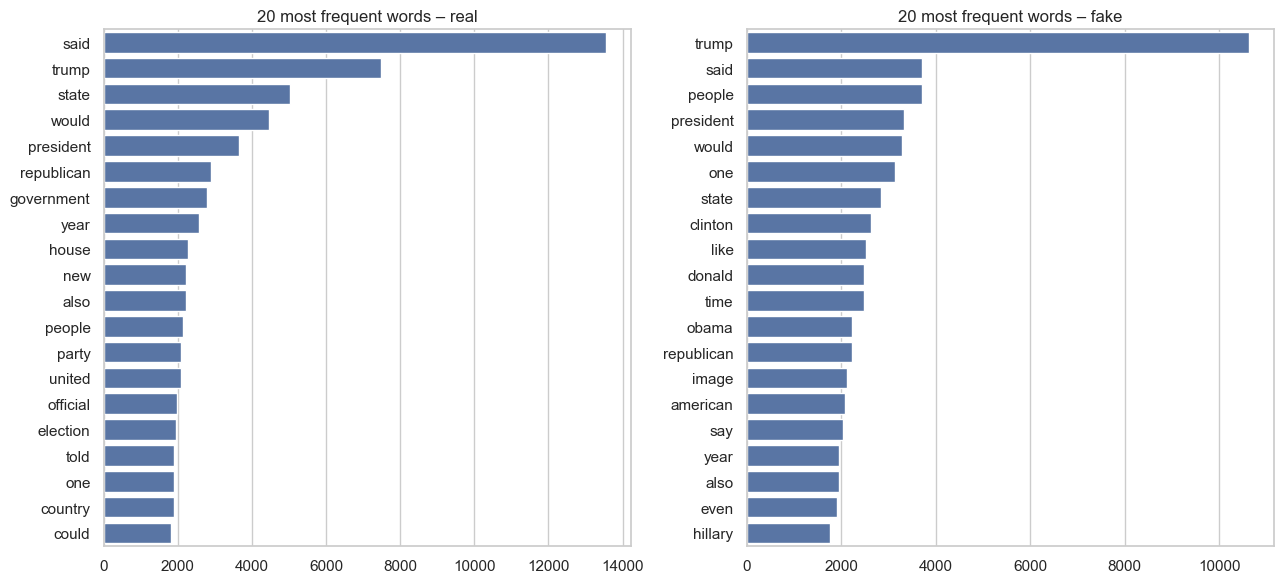

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, name in zip(axes, ["real", "fake"]):
    counter = Counter(tok for toks in sample.loc[sample["label_name"] == name, "tokens"] for tok in toks)
    words, freqs = zip(*counter.most_common(20))
    sns.barplot(x=list(freqs), y=list(words), ax=ax)
    ax.set_title(f"20 most frequent words – {name}")
plt.tight_layout()
plt.show()

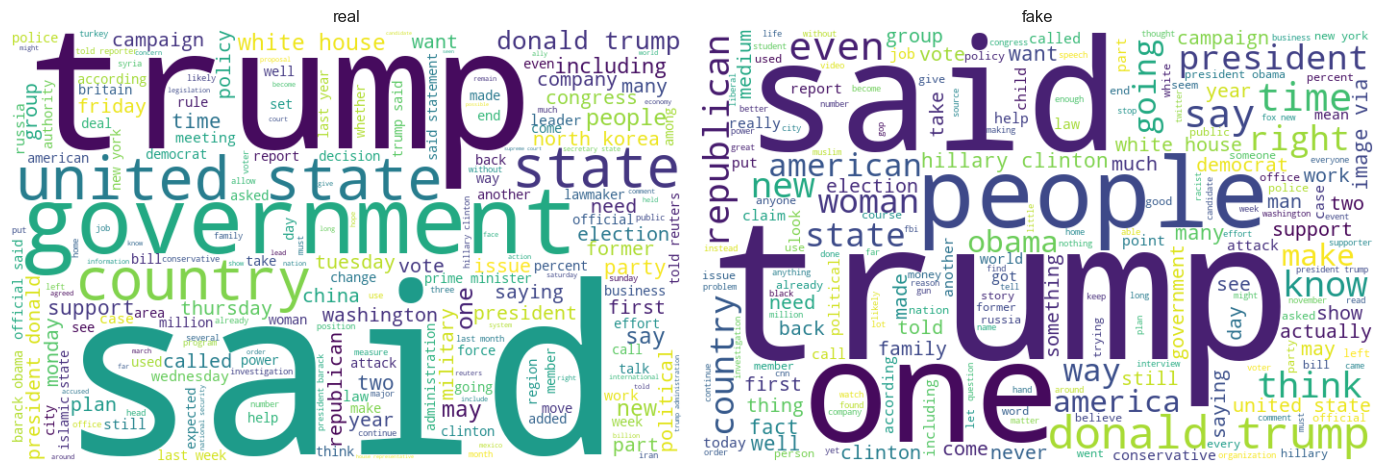

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, ["real", "fake"]):
    text = " ".join(" ".join(toks) for toks in sample.loc[sample["label_name"] == name, "tokens"])
    wc = WordCloud(width=700, height=450, background_color="white", random_state=RANDOM_STATE).generate(text)
    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(name)
plt.tight_layout()
plt.show()

## Most frequent bigrams per class

In [29]:
for name in ["real", "fake"]:
    counter = Counter(bg for toks in sample.loc[sample["label_name"] == name, "tokens"] for bg in ngrams(toks, 2))
    print(f"===== {name.upper()} =====")
    for bg, n in counter.most_common(15):
        print(f"{' '.join(bg):<30} {n}")
    print()

===== REAL =====
united state                   1647
donald trump                   1395
white house                    1096
president donald               773
north korea                    672
prime minister                 605
new york                       544
said statement                 492
last year                      478
official said                  477
last week                      473
islamic state                  469
trump said                     465
told reuters                   449
barack obama                   419

===== FAKE =====
donald trump                   2210
hillary clinton                993
image via                      954
united state                   818
white house                    751
president obama                534
new york                       474
president trump                446
fox news                       402
featured image                 339
barack obama                   321
supreme court                  296
trump supporter 

# Part 7 – Most characteristic words with TF-IDF

Frequent words are often shared by both classes (*trump*, *said*...). TF-IDF (Term Frequency – Inverse Document Frequency) gives more weight to words that are frequent in a document but rare in the rest of the corpus. We compute the average TF-IDF of each word in each class and keep the words with the largest **difference** between the two classes. This is a first idea of what the classifier will use.

In [30]:
sample["clean_text"] = sample["tokens"].str.join(" ")
tfidf = TfidfVectorizer(max_features=20000, min_df=5)
X = tfidf.fit_transform(sample["clean_text"])
vocab = np.array(tfidf.get_feature_names_out())

is_real = (sample["label_name"] == "real").to_numpy()
mean_real = np.asarray(X[is_real].mean(axis=0)).ravel()
mean_fake = np.asarray(X[~is_real].mean(axis=0)).ravel()
diff = mean_real - mean_fake

top = pd.DataFrame({
    "typical of REAL": vocab[np.argsort(diff)[::-1][:20]],
    "typical of FAKE": vocab[np.argsort(diff)[:20]],
})
top

,typical of REAL,typical of FAKE
0,said,trump
1,minister,image
2,state,like
3,government,via
4,china,hillary
5,reuters,clinton
6,korea,know
7,official,video
8,thursday,even
9,tuesday,woman


# Summary

1. **Size and splits:** 40,587 English news articles, already split into train (24,353), validation (8,117) and test (8,117). Each article has a title, a text and a label (1 = real, 0 = fake).
2. **Quality:** very clean. No missing values, only 2 empty texts (both fake), no duplicated text, no text with two different labels, and **no overlap** between train and validation/test – so the official splits can be used as they are. Some titles are repeated (2.4% of rows) but with different texts.
3. **Class balance:** 54% real / 46% fake in every split. Balanced enough to use accuracy, but we also report the F1-score (harmonic mean of precision and recall) for each class.
4. **Length:** fake titles are clearly longer (14 words on average vs 10 for real ones, with much more variation). Text lengths are similar (median 374 words for fake vs 358 for real), with more very short real articles.
5. **Biases found – the main finding:** the two classes come from different sources, and this leaves very visible clues:
   - 96% of real articles mention *(Reuters)* and 89% start with a dateline such as `WASHINGTON (Reuters) -`; no fake article does. The real class is essentially Reuters wire stories.
   - Fake articles carry blog / social media marks: a word in capitals in the title (72% vs 2%), *Featured image / image via* credits (45% vs 0.1%), *VIDEO* or *WATCH* in the title (28% vs 0%), Twitter handles (25% vs 1%), URLs (14% vs 0.2%), `!` or `?` in the title (15% vs 0.7%).
   - A model could reach a very high score from these clues alone, without "understanding" the news. They must be removed before training (done in notebook 2).
6. **Words typical of each class:** after removing the dateline, real articles use agency vocabulary – *said*, days of the week, *minister*, *government*, *official*, *told reuters*, *north korea*, *islamic state*. Fake articles use more opinion and online vocabulary – *image via*, *featured image*, *hillary clinton*, *president obama*, *fox news*, *like*, *know*, *video*, *http*. Both talk mostly about the same topic (US politics, Trump, Clinton, Obama), so the difference is more about **style and source** than about subject.
7. **Limits of the dataset:**
   - Period: mostly 2015-2017 (the years mentioned in the texts peak in 2016: US election and first year of the Trump presidency).
   - Topic: mostly US politics and world news; English only.
   - Labels are given **by source** (Reuters = real, a list of unreliable websites = fake), not checked article by article: some labels may be wrong (confirmed in notebook 2).
   - The model will learn "Reuters style vs blog style" as much as "true vs false". It may fail on real articles written in another style (e.g. a French newspaper translated, an opinion column) or on fake news written in a neutral agency style.

**Decisions for notebook 2:** remove the 2 empty texts, keep the official splits, use title + text as input, remove the source clues with regular expressions, and compare the score with and without this cleaning.